# Математички методи за машинско учење 2025/2026
## Домаћи задатак број 6

<div class="alert alert-block alert-danger">
<b>Име и презиме студента:</b> Jovan Paunović

<b>Број индекса:</b> 2122
    
</div>    

<div class="alert alert-block alert-info">
<b>Упутство за израду и предају домаћег задатака: </b> 
    
    1. Пре почетка израде промените име датотеке у 06Domaci_Ime_Prezime. (убаците своје име и презиме) 
    2. Попуните ћелију испод наслова одговарајућим подацима. 
    1. Употреба ћирилице није обавезна за предају домаћег задатка.
    4. За решавање задатака, уколико је потребно, отворите испод текста задатка додатне ћелије за уписивање текстуалног одговора (Markdown) или програмског кода (Code).
    1. Сва израчунавања, уколико је потребно, вршити у Python-у.
    5. Након завршетка израде решења домаћег Notebook документ сачувати у pdf формату и проследити га наставнику. То можете да урадите или кроз Teams или на мејл адресу jovana.dzunic@elfak.ni.ac.rs

</div> 

In [3]:
import numpy as np
import numpy.random as rndm
import matplotlib as mplb
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.metrics.pairwise import rbf_kernel
import time
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from scipy.linalg import orth

**Задатак 1.**  У анализи података, Фробенијусова норма мери укупну „енергију” матрице, док нуклеарна норма (норма трага) служи као конвексна апроксимација ранга (нпр. код *Matrix Completion* проблема). Спектрална норма, тј. норма индукована векторском $l_2$ нормом, користи се за процену стабилности алгоритама и нумеричких метода. Повезана је са доминантним структурама у подацима. 

| Норма        | Шта мери?                           | Математички еквивалент                 |
|--------------|--------------------------------------|-----------------------------------------|
| Нуклеарна    | Збир свих сингуарних вредности       | Апроксимација ранга                     |
| Фробенијусова| Квадратни корен збира квадрата       | Укупна енергија / Варијанса             |
| Спектрална   | Највећа сингуарна вредност           | Максимално истезање / Стабилност        |

Посматрајмо матрицу малог ранга $A_0 \in \mathcal{M}_{100 \times 100}$ (нпр. $r=5$) која је контаминирана адитивним Гаусовим шумом $\sigma E$, где су елементи $E_{ij} \sim \mathcal{N}(0, 1),$ тако да је резултујућа матрица $A = A_0 + \sigma E.$

**а)** 
1. Генерисати $A_0$ ранга 5 и шум $E$ тако да је $\|A_0\|_F \approx \sigma \|E\|_F$. Израчунати нуклеарну, Фробенијусову и спектралну норму за $A_0$ и $A$.
2. Проверити теоријску неједнакост: $\|A\|_2 \le \|A\|_F \le \|A\|_N$. 
3. Дискутовати: Која норма је најосетљивија на шум (највише расте релативно у односу на $A_0$)? Прокоментарисати у којим спектралним конфигурацијама су ове неједнакости „оштре” (sharp), а у којим случајевима су „лабаве”.
4. Како се мења спектрална норма $\|A\|_2$ (највећа сингуларна вредност) у односу на $\|A_0\|_2$? Објаснити зашто шум увек „надувава” спектар матрице.

(10 поена)

In [4]:
np.random.seed(42)

n = 100
r = 5

U = np.random.randn(n, r)
V = np.random.randn(r, n)
A0 = U @ V

E = np.random.randn(n, n)

norm_A0_F = np.linalg.norm(A0, 'fro')
norm_E_F = np.linalg.norm(E, 'fro')

sigma = norm_A0_F / norm_E_F

A = A0 + sigma * E

U0, S0, Vt0 = np.linalg.svd(A0)
A0_spec = S0[0]
A0_fro = np.linalg.norm(A0, 'fro')
A0_nuc = np.linalg.norm(A0, 'nuc')

U_A, S_A, Vt_A = np.linalg.svd(A)
A_spec = S_A[0]
A_fro = np.linalg.norm(A, 'fro')
A_nuc = np.linalg.norm(A, 'nuc')

print("Norme za A0")
print(f"Spektralna: {A0_spec:.2f}")
print(f"Frobenijusova: {A0_fro:.2f}")
print(f"Nuklearna: {A0_nuc:.2f}")

print("\nNorme za A (A0 + šum)")
print(f"Spektralna: {A_spec:.2f}")
print(f"Frobenijusova: {A_fro:.2f}")
print(f"Nuklearna: {A_nuc:.2f}")

print("\nProvera nejednakosti")
print(f"Za A0: {A0_spec:.2f} <= {A0_fro:.2f} <= {A0_nuc:.2f} -> {A0_spec <= A0_fro <= A0_nuc}")
print(f"Za A : {A_spec:.2f} <= {A_fro:.2f} <= {A_nuc:.2f} -> {A_spec <= A_fro <= A_nuc}")

print("\nRelativno povećanje usled šuma (A / A0)")
print(f"Nuklearna:    {A_nuc/A0_nuc:.2f}x")
print(f"Frobeniusova: {A_fro/A0_fro:.2f}x")
print(f"Spektralna:   {A_spec/A0_spec:.2f}x")

Norme za A0
Spektralna: 118.88
Frobenijusova: 216.48
Nuklearna: 474.50

Norme za A (A0 + šum)
Spektralna: 124.76
Frobenijusova: 306.93
Nuklearna: 2197.42

Provera nejednakosti
Za A0: 118.88 <= 216.48 <= 474.50 -> True
Za A : 124.76 <= 306.93 <= 2197.42 -> True

Relativno povećanje usled šuma (A / A0)
Nuklearna:    4.63x
Frobeniusova: 1.42x
Spektralna:   1.05x


Kao što vidimo iz rezultata, nuklearna norma najviše raste (povećava se preko $4.5$ puta). Matrica $A_0$ ima rang $r=5$, što znači da ima samo $5$ ne-nula singularnih vrednosti. Dodavanjem Gausovog šuma, preostalih 95 singularnih vrednosti (koje su bile nula) postaju pozitivne, i sve one zajedno drastično povećavaju zbir. Spektralna norma najmanje raste jer zavisi samo od najveće singularne vrednosti $\sigma_1$.

Što se tiče nejednakosti
$$
\|A\|_2 \leq \|A\|_F \leq \|A\|_N
$$

Kada matrica ima rang $1$ (ima jednu ne-nultu singularnu vrednost), sve tri norme se poklapaju:
$$
\|A\|_2 = \|A\|_F = \|A\|_N.
$$

Kada matrica ima veliki rang (mnogo singularnih vrednosti), razlike između normi postaju velike:
$$
\|A\|_2 \ll \|A\|_F \ll \|A\|_N.
$$

To možemo da vidimo i pomoću sledećeg Python koda:

In [5]:
def matrix_norms(M):
    s = np.linalg.svd(M, compute_uv=False)
    return np.max(s), np.linalg.norm(M, 'fro'), np.sum(s)

np.random.seed(42)
# Rang 1
u = np.random.randn(100,1)
v = np.random.randn(100,1)
A_1 = u @ v.T

# Rang 100
I = np.eye(100)

print("Rang 1 matrica:")
print(matrix_norms(A_1))

print("\nRang 100 matrica:")
print(matrix_norms(I))

Rang 1 matrica:
(np.float64(86.33131566963837), np.float64(86.33131566963836), np.float64(86.3313156696384))

Rang 100 matrica:
(np.float64(1.0), np.float64(10.0), np.float64(100.0))


Spektralna norma matrice $A$ se relativno malo povećala u odnosu na spektralnu normu matrice $A_0$. 
Šum dodaje nove komponente u svim pravcima tj. dodavanje šuma uvek povećava spektar, jer se pojavljuje nova dominantna vrednost. Zbog toga šum uvek "naduvava" spektar matrice.

**б)** 
1. Применити SVD на матрицу $A$. Конструисати серију најбољих апроксимација $A_k$ за $k=1, \dots, 20$. 
2. Нацртати график функције грешке апроксимације $f(k) = \|A - A_k\|_F$. 
3. Пронаћи „колено” (elbow) на графику и повезати га са стварним рангом матрице $A_0$. Дискутовати како интензитет шума $\sigma$ утиче на заобљеност колена и зашто је ова метода често субјективна.

(5 поена)

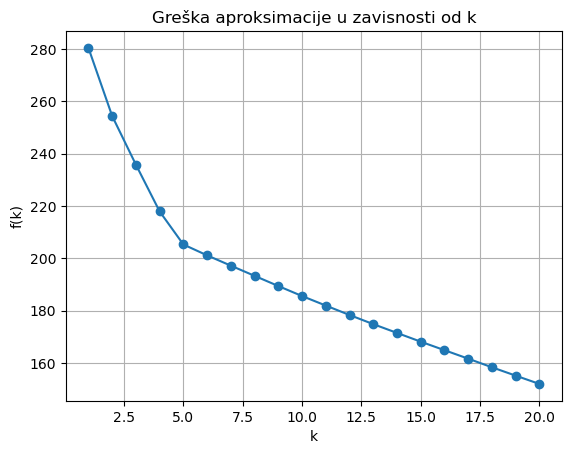

In [6]:
U, S, Vt = np.linalg.svd(A)

errors = []
for k in range(1, 21):
    Ak = (U[:, :k] * S[:k]) @ Vt[:k, :]
    errors.append(np.linalg.norm(A - Ak, 'fro'))

plt.plot(range(1, 21), errors, marker='o')
plt.xlabel("k")
plt.ylabel("f(k)")
plt.title("Greška aproksimacije u zavisnosti od k")
plt.grid(True)
plt.show()

Sa grafika vidimo da greška brzo opada do $k=5$, nakon čega opada slabije. To mesto na grafiku je "koleno" i ono se poklapa sa stvarnim rangom matrice $A_0$ (njen rang je $5$).

Kada postoji mali šum (malo $\sigma$) onda je koleno oštro i jasno definisano. Ako postoji veliki šum (veliko $\sigma$) onda je koleno više zaobljeno i teže se uočava. To je zbog toga što u tom slučaju singularne vrednosti šuma postaju uporedive sa singularnim vrednostima matrice $A_0$.

Ova metoda je često subjektivna zato što zavisi od vizuelne procene i intenziteta šuma. Kada podaci poseduju dosta šuma, onda se koleno ne vidi jasno i ne postoji strogo definisan matematički kriterijum koji određuje gde se koleno tačno nalazi na grafiku, već to mora odokativno da se odredi.

***

**в) Marchenko-Pastur закон и оптимални праг за PCA:**

Теорија случајних матрица нуди прецизније решење за раздвајање сигнала од шума. За квадратну матрицу димензија $n \times n$ чији су елементи $N(0, \sigma^2)$, Marchenko-Pastur закон предвиђа да ће се сингуларне вредности „чистог шума” налазити унутар опсега чија је горња граница (тзв. *edge*):
$$\lambda_{max} \approx 2 \sigma \sqrt{n}$$
Све сингуларне вредности изнад овог прага сматрају се релевантним сигналом.

1. Извршити SVD матрице $A$. Нацртати хистограм свих сингуларних вредности.
2. На истом графику означити теоријски Marchenko-Pastur праг. 
3. Израчунати нумерички ранг матрице $A$ користећи овај праг. Упоредити добијени број са стварним рангом $A_0$.
4. **Деноисинг:** Конструисати апроксимацију $\tilde{A}$ задржавајући само сингуларне вредности изнад MP прага. Израчунати релативну грешку $\|\tilde{A} - A_0\|_F / \|A_0\|_F$. Дискутовати зашто је ово решење робусније од фиксирања броја компоненти „на слепо”.

(10 поена)

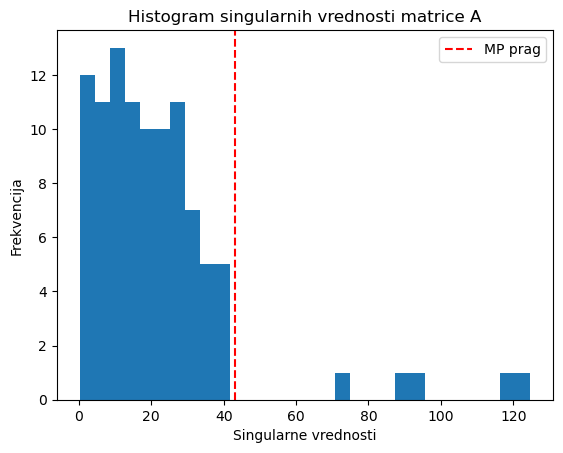

Numerički rang: 5
Stvarni rang A0: 5
Relativna greška: 0.3282970311160851


In [7]:
U, S, Vt = np.linalg.svd(A)

plt.hist(S, bins=30)
lambda_max = 2 * sigma * np.sqrt(n)
plt.axvline(lambda_max, color='red', linestyle='--', label='MP prag')
plt.xlabel("Singularne vrednosti")
plt.ylabel("Frekvencija")
plt.title("Histogram singularnih vrednosti matrice A")
plt.legend()
plt.show()

r_num = np.sum(S > lambda_max)
print("Numerički rang:", r_num)
print("Stvarni rang A0:", r)

keep = S > lambda_max
At = U[:, keep] @ np.diag(S[keep]) @ Vt[keep, :]
rel_error = np.linalg.norm(At - A0, 'fro') / np.linalg.norm(A0, 'fro')
print("Relativna greška:", rel_error)

Dobijeni numerički rang se poklapa sa stvarnim rangom. Na histogramu vidimo veliku gomilu malih singularnih vrednosti koje se nalaze sa leve strane MP praga i to su singularne vrednosti koje potiču od šuma. Desno od MP praga imamo izolovane i značajno veće singularne vrednosti i one se smatraju korisnim signalom.

Ovo rešenje je robusnije od fiksiranja broja komponenti "na slepo" jer ako unapred fiksiramo broj komponenti, rizikujemo da pogrešno odsečemo signal ili da uključimo šum. Pomoću Marchenko-Pastur zakona, određujemo prag koji adaptivno razdvaja signal od šuma, pa je metoda stabilnija i manje subjektivna.

***

**Задатак 2.**  Кондициони број и стабилност линеарне регресије

У машинском учењу, проблем најмањих квадрата $\|Ax - b\|_2$ постаје нумерички нестабилан ако су колоне матрице $A$ скоро линеарно зависне (феномен мултиколинеарности). Овај задатак истражује границе машинске тачности кроз призму спектралне декомпозиције.

**а)** Креирати матрицу података $A \in \mathcal{M}_{100 \times 10}$ где је првих 9 колона насумично генерисано из расподеле $\mathcal{N}(0,1)$. Десету колону дефинисати као линеарну комбинацију прве две уз додатак минималног шума: $A_{:, 9} = A_{:, 0} + A_{:, 1} + \epsilon$, где је $\epsilon \sim \mathcal{N}(0, 10^{-k})$. 
- Прокоментарисати како параметар $k$ утиче на утиче на линеарну зависност колона матрице $A.$

(5 поена)

In [8]:
np.random.seed(42)

n = 100
m = 10

A_base = np.random.randn(n, m-1)

k_values = [1, 3, 5, 8, 12, 15]

for k in k_values:
    A = np.zeros((n, m))
    
    A[:, :9] = A_base
    
    epsilon = np.random.randn(n) * (10.0**(-k))
    
    A[:, 9] = A[:, 0] + A[:, 1] + epsilon
    
    cond_A = np.linalg.cond(A)
    
    print(f"k: {k}, Nivo šuma: 1e-{k}, Kondicioni broj: {cond_A:.2e}")

k: 1, Nivo šuma: 1e-1, Kondicioni broj: 3.22e+01
k: 3, Nivo šuma: 1e-3, Kondicioni broj: 3.39e+03
k: 5, Nivo šuma: 1e-5, Kondicioni broj: 2.81e+05
k: 8, Nivo šuma: 1e-8, Kondicioni broj: 3.18e+08
k: 12, Nivo šuma: 1e-12, Kondicioni broj: 3.23e+12
k: 15, Nivo šuma: 1e-15, Kondicioni broj: 2.97e+15


Kako se $k$ povećava, tako je nivo šuma sve manji. Ako je $k$ malo, onda je šum veliki, pa poslednja kolona i nije baš linearna kombinacija prve dve kolone, a ako se $k$ dovoljno poveća, onda se šum dosta smanji pa je poslednja kolona matrice $A$ skoro linearna kombinacija prve dve kolone, što dovodi do fenomena multikolinearnosti.

To dalje uzrokuje da je kondicioni broj sve veći kako se $k$ povećava, a on nam direktno govori koliko je problem numerički stabilan. Ako je kondicioni broj veliki, onda je i problem prilično nestabilan. Dakle, povećanjem $k$ problem postaje sve nestabilniji.

**б)** Симулирати систем $Ax = b$ тако што ћете дефинисати тачно решење $x_{true} = [1, 1, \dots, 1]^T$ и израчунати десну страну као $b = A x_{true}$. Користећи функцију за решавање система (нпр. `np.linalg.solve`), израчунати нумеричко решење $\hat{x}$.
1. Упоредити грешке $\|\hat{x} - x_{true}\|_2$ за $k=2$ и $k=14$. 
2. Израчунати број изгубљених значајних цифара. 
3. Проверити важење процене: $\text{изгубљене цифре} \approx \log_{10}(\kappa(A))$. Повезати резултате са чињеницом да стандардна *float64* прецизност има око 15–17 значајних децималних цифара.

(10 поена)

In [9]:
n = 100
m = 10
np.random.seed(42)

A_base = np.random.randn(n, m-1).astype(np.float64)

x_true = np.ones(m, dtype=np.float64)

epsM = np.finfo(np.float64).eps
print(f"Mašinsko epsilon: {epsM:.2e}\n")

for k in [2, 14]:
    epsilon = np.random.randn(n).astype(np.float64) * (10**(-k))
    col10 = A_base[:,0] + A_base[:,1] + epsilon
    A = np.column_stack([A_base, col10])

    b = A @ x_true

    # rešavanje sistema pomoću normalnih jednačina, cilj je pokazati njihovu lošu uslovljenost
    ATA = A.T @ A
    ATb = A.T @ b

    x_hat = np.linalg.solve(ATA, ATb)

    error = np.linalg.norm(x_hat - x_true, 2)

    kappa_A = np.linalg.cond(A)
    kappa_ATA = np.linalg.cond(ATA)

    lost_digits_A = np.log10(kappa_A)
    lost_digits_ATA = np.log10(kappa_ATA)

    m_digits = int(np.floor(-np.log10(2 * kappa_ATA * epsM)))

    print(f"Rezultati za k = {k}")
    print(f"Greška ||x_hat - x_true||_2: {error:.2e}")
    print(f"Kondicioni broj kappa(A): {kappa_A:.2e}")
    print(f"Kondicioni broj kappa(A^T A): {kappa_ATA:.2e}")
    print(f"Izgubljene cifre (A): {lost_digits_A:.2f}")
    print(f"Izgubljene cifre (A^T A): {lost_digits_ATA:.2f}")
    print(f"Preostale cifre: {16 - lost_digits_ATA:.2f}")
    print(f"Procena značajnih cifara: {m_digits}")
    print()

Mašinsko epsilon: 2.22e-16

Rezultati za k = 2
Greška ||x_hat - x_true||_2: 3.18e-11
Kondicioni broj kappa(A): 3.23e+02
Kondicioni broj kappa(A^T A): 1.04e+05
Izgubljene cifre (A): 2.51
Izgubljene cifre (A^T A): 5.02
Preostale cifre: 10.98
Procena značajnih cifara: 10

Rezultati za k = 14
Greška ||x_hat - x_true||_2: 5.80e+00
Kondicioni broj kappa(A): 3.38e+14
Kondicioni broj kappa(A^T A): 1.29e+16
Izgubljene cifre (A): 14.53
Izgubljene cifre (A^T A): 16.11
Preostale cifre: -0.11
Procena značajnih cifara: -1



Vidimo da data procena izgubljenih cifara važi. Za slučaj $k=2$, šum je veliki, poslednja kolona nije skoro linearna kombinacija prve dve kolone, kondicioni broj nije ogroman i sistem je skoro stabilan. Procena pokazuje da je broj izgubljenih cifara oko 5 (ako gledamo normalne jednačine), što kad se oduzme od 16 (jer je to otprilike broj značajnih cifara kod float64) daje oko 10 ili 11 značajnih cifara. To se poklapa sa brojem značajnih cifara izračunatih preko nejednačine  $\kappa(A)\epsilon_M\leq\dfrac12\cdot10^{-m}$. Dakle, u ovom slučaju greška je mala i imamo dosta značajnih cifara.

Kad je $k=14$, šum je mali pa poslednja kolona postaje skoro linearna kombinacija prve dve kolone matrice $A$. Kondicioni broj matrice $A$ postaje ogroman, a matrice $A^TA$ još veći. Procena na osnovu kondicionog broja matrice $A^TA$ pokazuje da je gubitak značajnih cifara oko 16. Ako to oduzmemo od 16 onda nam ne ostaje nijedna značajna cifra u rezultatu. Broj značajnih cifara dobijen preko nejednačine $\kappa(A)\epsilon_M\leq\dfrac12\cdot10^{-m}$ je približno 0. Dakle i u ovom slučaju su procene broja značajnih cifara bliske, ali sada ukazuju da je rešenje nepouzdano.

**в)** На основу претходних резултата, написати кратак коментар (5–10 реченица) у коме се:

- објашњава зашто скоро линеарна зависност колона доводи до лоше кондиционираности,
- повезује параметар шума $k$ са геометријом колона матрице $A$,
- интерпретира значење кондиционог броја у контексту стабилности линеарне регресије,
- формулише практична препорука за рад са реалним подацима.

(10 поена)

Skoro linearna zavisnost kolona matrice $A$ znači da postoji kolona koja se može gotovo izraziti kao linearna kombinacija ostalih. Geometrijski, to znači da su odgovarajući vektori u $\mathbb{R}^{100}$ skoro kolinearni, odnosno da zauzimaju gotovo isti pravac. Posledica toga je da najmanja singularna vrednost $\sigma_{\min}$ postaje veoma mala, pa kondicioni broj 
$$
\kappa(A) = \frac{\sigma_{\max}}{\sigma_{\min}}
$$
postaje veoma velik. 

Parametar šuma $k$ direktno utiče na stepen te zavisnosti: kako $k$ raste, šum opada, deseta kolona postaje sve bliža tačnoj linearnoj kombinaciji prve dve, a matrica postaje gotovo singularna. U tom slučaju i mala promena u vektoru $b$ ili zaokruživanje usled mašinske aritmetike može izazvati veliku promenu u rešenju $\hat{x}$. Zato kondicioni broj meri osetljivost rešenja na greške u podacima i predstavlja indikator numeričke stabilnosti problema linearne regresije.

U praksi, velika vrednost $\kappa(A)$ ukazuje na multikolinearnost i potencijalno nepouzdane koeficijente regresije. Preporučuje se primena regularizacije (npr. Ridge regresije), uklanjanje ili kombinovanje skoro zavisnih atributa, kao i standardizacija podataka kako bi se poboljšala numerička stabilnost modela.

***

**Задатак 3.** У контексту линеарне регресије, решење проблема најмањих квадрата често се тражи преко нормалних једначина: $(A^TA)x = A^Tb$. Овај задатак истражује зашто је овај приступ нумерички ризичан и како регуларизација „лечи” лошу кондиционираност.

**а)** Нека је $A \in \mathcal{M}_{m \times n}$ матрица пуног ранга по колонама. 
1. Користећи SVD декомпозицију матрице $A$, доказати да важи $\kappa(A^TA) = \kappa(A)^2$, где је $\kappa$ кондициони број у спектралној норми.
2. Дискутовати импликације овог резултата: Ако матрица $A$ има кондициони број $10^8$ (што је чест случај у реалним подацима), шта се дешава са стабилношћу система нормалних једначина у стандардној двострукој прецизности? 

(5 поена)

SVD dekompozicija matrice $A$ je:
$$
A = U \Sigma V^T,
$$
gde su $U$ i $V$ ortogonalne matrice, a 
$$
\Sigma = \operatorname{diag}(\sigma_1, \dots, \sigma_n), \quad \sigma_1 \ge \dots \ge \sigma_n > 0.
$$

Tada važi
$$
A^T A = (U \Sigma V^T)^T (U \Sigma V^T)
= V \Sigma^T U^T U \Sigma V^T
= V \Sigma^2 V^T,
$$
jer je $U^T U = I$. Dakle, singularne vrednosti matrice $A^T A$ jednake su $\sigma_i^2$. 

Kondicioni broj u spektralnoj normi definisan je kao
$$
\kappa(A) = \frac{\sigma_{\max}}{\sigma_{\min}} = \frac{\sigma_1}{\sigma_n}.
$$
Za matricu $A^T A$ dobijamo
$$
\kappa(A^T A) 
= \frac{\sigma_1^2}{\sigma_n^2}
= \left(\frac{\sigma_1}{\sigma_n}\right)^2
= \kappa(A)^2.
$$

Dakle, zadata jednakost važi.

Iz ovoga zaključujemo da ako je, na primer,
$$
\kappa(A) = 10^8,
$$
onda je
$$
\kappa(A^T A) = 10^{16}.
$$


U standardnoj dvostrukoj preciznosti (*float64*), postoji oko $15-17$ značajnih cifara. Kondicioni broj $10^{16}$ znači da se može izgubiti približno
$$
\log_{10}(10^{16}) = 16
$$
značajnih cifara. Time se praktično gubi celokupna raspoloživa preciznost i rešenje sistema normalnih jednačina može postati numerički nepouzdano ili potpuno neupotrebljivo.

Zato je rešavanje problema najmanjih kvadrata preko normalnih jednačina numerički rizično kod loše kondicioniranih matrica.

**б)** Креирати матрицу $A \in \mathcal{M}_{100 \times 10}$ такву да је њена најмања сингуларна вредност $\sigma_{min} = 10^{-6}$ (можете користити SVD конструкцију или методи из Задатка 2).
1. Дефинисати десну страну $b = A x_{true}$.
2. Симулирати малу пертурбацију (грешку мерења или шум) $b \to b + \delta b$, где је $\|\delta b\|_2 = 10^{-3}$.
3. Решити систем нормалних једначина за оригинални и пертурбовани вектор. Измерити релативну промену решења $\|\delta x\|_2 / \|x\|_2$. 
4. Упоредити овај резултат са теоријском границом коју предвиђа $\kappa(A^TA)$. Прокоментарисати стабилност алгоритма.

(10 поена)

Posmatrajući normalne jednačine kao klasičan linearni sistem $My = c$, gde je $M = A^T A$, $y = x$, i $c = A^T b$, perturbacija $\delta b$ izaziva perturbaciju desne strane $\delta c = A^T \delta b$.
Teorijska gornja granica relativne greške data je nejednakošću:$$\frac{\|\delta x\|_2}{\|x\|_2} \le \kappa(A^T A) \frac{\|A^T \delta b\|_2}{\|A^T b\|_2}$$

In [8]:
np.random.seed(42)

m = 100
n = 10

U, _ = np.linalg.qr(np.random.randn(m, n))
V, _ = np.linalg.qr(np.random.randn(n, n))

sing_vals = np.linspace(1, 1e-6, n)
S = np.diag(sing_vals)

A = U @ S @ V.T

sigma_min = sing_vals[-1]
kappa_A = sing_vals[0] / sing_vals[-1]
kappa_ATA = kappa_A**2

print("sigma_min: ", sigma_min)
print("kappa(A): ", kappa_A)
print("kappa(A^T A): ", kappa_ATA)

x_true = np.ones(n)
b = A @ x_true

delta_b = np.random.randn(m)
delta_b = delta_b / np.linalg.norm(delta_b) * 1e-3
print("Norma delta_b: ", np.linalg.norm(delta_b))
b_pert = b + delta_b

ATA = A.T @ A
ATb = A.T @ b
ATb_pert = A.T @ b_pert

x_hat = np.linalg.solve(ATA, ATb)
x_hat_pert = np.linalg.solve(ATA, ATb_pert)

delta_x = x_hat_pert - x_hat

rel_change = np.linalg.norm(delta_x) / np.linalg.norm(x_hat)
rel_b = np.linalg.norm(delta_b) / np.linalg.norm(b)

print("\nRelativna promena desne strane:", rel_b)
print("Relativna promena rešenja:", rel_change)

delta_c = A.T @ delta_b
rel_change_c = np.linalg.norm(delta_c) / np.linalg.norm(ATb)
theoretical_bound = kappa_ATA * rel_change_c
print("Teorijska granica:", theoretical_bound)

sigma_min:  1e-06
kappa(A):  1000000.0
kappa(A^T A):  1000000000000.0
Norma delta_b:  0.001

Relativna promena desne strane: 0.0004762626801146703
Relativna promena rešenja: 36.37444355344274
Teorijska granica: 116816494.11663333


Matrica $A$ konstruisana je tako da ima kondicioni broj $\kappa(A) = 10^6$. Kao što je dokazano u delu pod $(a)$, prelazak na sistem normalnih jednačina $(A^T A)x = A^T b$ kvadrira ovaj kondicioni broj, dovodeći do:

$$\kappa(A^T A) = (10^6)^2 = 10^{12}$$

Relativna greška (perturbacija) koju smo veštački uneli u vektor $b$ je izuzetno mala. Međutim, kada rešimo sistem normalnih jednačina za perturbovani vektor $b + \delta b$, primećujemo da je relativna greška u rešenju $x$, tj. odnos $\frac{\|\delta x\|_2}{\|x\|_2}$, dosta veliki. Mala greška merenja je katastrofalno pojačana zbog loše uslovljenosti matrice sistema.

Ovaj primer pokazuje zašto se normalne jednačine smatraju numerički nestabilnim i izuzetno rizičnim. Konstrukcija matrice $A^T A$ neminovno gubi informacije zbog kvadriranja kondicionog broja i ograničenja standardne float64 aritmetike.

**в)** Уводимо параметар регуларизације $\lambda > 0$ и посматрамо систем $(A^TA + \lambda I)x = A^Tb$. Означимо регуларизовану матрицу са $G_\lambda = A^TA + \lambda I$.
1. Како се сингуларне вредности матрице $G_\lambda$ односе према сингуларним вредностима матрице $A^TA$? 
2. Израчунати и нацртати график зависности кондиционог броја $\kappa(G_\lambda)$ од параметра $\lambda$ за $\lambda \in [10^{-9}, 10^1]$. 
3. Анализирати „Bias-Variance Trade-off”: Експериментално показати да повећање $\lambda$ смањује норму решења и његову осетљивост на шум (стабилност), али повећава растојање од тачног решења (пристрасност/bias). Пронаћи $\lambda$ које даје минималну укупну грешку у присуству шума. 

(10 поена)

Za matricu $A$ sa SVD dekompozicijom $A=U\Sigma V^T$, važi $A^TA=V\Sigma ^2V^T$.

Za sledeći izraz:

$$
G_\lambda = A^T A + \lambda I
$$

važi

$$
A^T A = V \Sigma^2 V^T
$$

i

$$
I = V I V^T
$$

(jer je $V$ ortogonalna matrica),

Onda možemo da pišemo:

$$
\lambda I = V (\lambda I) V^T
$$

Ako to spojimo u konačan izraz:

$$
G_\lambda
= V \Sigma^2 V^T + V (\lambda I) V^T
= V (\Sigma^2 + \lambda I) V^T
$$

Ovo znači da su singularne vrednosti matrice $G_{\lambda }$ jednake $\sigma _i^2+\lambda$ , gde su $\sigma _i$ singularne vrednosti matrice $A$. Dakle, regularizacija pomera sve singularne vrednosti naviše za $\lambda$ , čime se povećava najmanja singularna vrednost i smanjuje kondicioni broj koji se onda računa po sledećoj formuli:
$$
\kappa(G_\lambda) =
\frac{\sigma_{\max}^2 + \lambda}
{\sigma_{\min}^2 + \lambda}.
$$

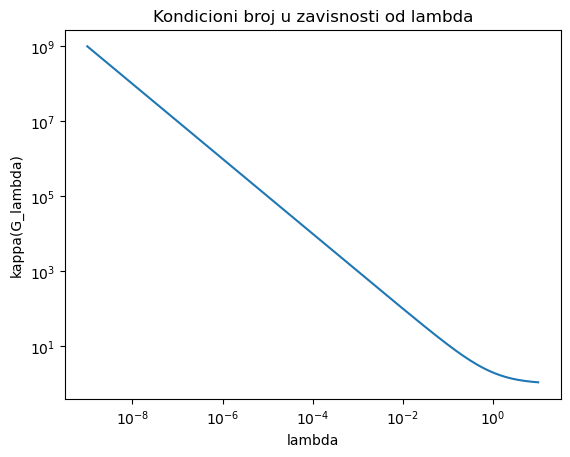

1.09999999999989


In [9]:
# možemo da iskoristimo matricu A iz prethodnog dela zadatka
U, S, Vt = np.linalg.svd(A, full_matrices=False)

sigma_max2 = S.max()**2
sigma_min2 = S.min()**2

lambdas = np.logspace(-9, 1, 200)
kappa_vals = (sigma_max2 + lambdas) / (sigma_min2 + lambdas)

plt.figure()
plt.loglog(lambdas, kappa_vals)
plt.xlabel("lambda")
plt.ylabel("kappa(G_lambda)")
plt.title("Kondicioni broj u zavisnosti od lambda")
plt.show()

print(kappa_vals.min())

Za veoma malo $\lambda$, kondicioni broj je veliki (kao kondicioni broj matrice $A^TA$). Povećanjem $\lambda$, kondicioni broj matrice $G_{\lambda}$ postaje sve bliži jedinici.

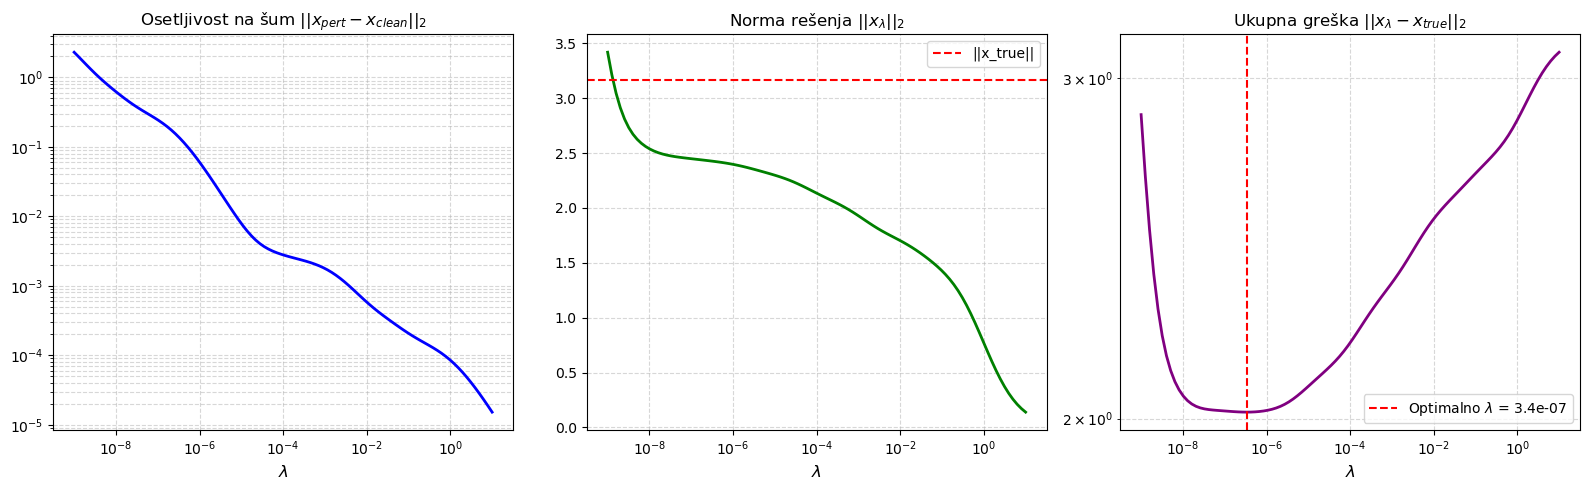

Optimalno lambda koje minimizuje ukupnu grešku: 3.35e-07
Minimalna greška pri optimalnom lambda: 2.0153


In [10]:
# ponovno kreiranje matrice A da bi bila nezavisna ćelija
np.random.seed(42)
n, m = 100, 10
U, _ = np.linalg.qr(np.random.randn(n, m))
V, _ = np.linalg.qr(np.random.randn(m, m))
S_vals = np.logspace(0, -6, m)
A = U @ np.diag(S_vals) @ V.T

x_true = np.ones(m)
b = A @ x_true
delta_b_dir = np.random.randn(n)
delta_b = (delta_b_dir / np.linalg.norm(delta_b_dir)) * 1e-3
b_pert = b + delta_b

lambda_vals = np.logspace(-9, 1, 100)
sensitivity_vals = []
norm_x_vals = []
error_vals = []

ATA = A.T @ A
ATb = A.T @ b
ATb_pert = A.T @ b_pert
I = np.eye(m)

for lam in lambda_vals:
    G_lam = ATA + lam * I
    
    x_lam_pert = np.linalg.solve(G_lam, ATb_pert)
    x_lam_clean = np.linalg.solve(G_lam, ATb)
    
    # osetljivost rešenja na šum
    sensitivity = np.linalg.norm(x_lam_pert - x_lam_clean)
    sensitivity_vals.append(sensitivity)
    
    # norma perturbovanog rešenja
    norm_x_vals.append(np.linalg.norm(x_lam_pert))
    
    # ukupna greška u odnosu na tačno rešenje
    error_vals.append(np.linalg.norm(x_lam_pert - x_true))

min_err_idx = np.argmin(error_vals)
opt_lam = lambda_vals[min_err_idx]
min_err = error_vals[min_err_idx]

fig, axs = plt.subplots(1, 3, figsize=(16, 5))

axs[0].plot(lambda_vals, sensitivity_vals, 'b-', lw=2)
axs[0].set_xscale('log')
axs[0].set_yscale('log')
axs[0].set_title(r'Osetljivost na šum $||x_{pert} - x_{clean}||_2$', fontsize=12)
axs[0].set_xlabel(r'$\lambda$', fontsize=12)
axs[0].grid(True, which="both", ls="--", alpha=0.5)

axs[1].plot(lambda_vals, norm_x_vals, 'g-', lw=2)
axs[1].axhline(np.linalg.norm(x_true), color='r', linestyle='--', label='||x_true||')
axs[1].set_xscale('log')
axs[1].set_title(r'Norma rešenja $||x_\lambda||_2$', fontsize=12)
axs[1].set_xlabel(r'$\lambda$', fontsize=12)
axs[1].legend()
axs[1].grid(True, which="both", ls="--", alpha=0.5)

axs[2].plot(lambda_vals, error_vals, 'purple', lw=2)
axs[2].axvline(opt_lam, color='r', linestyle='--', label=rf'Optimalno $\lambda$ = {opt_lam:.1e}')
axs[2].set_xscale('log')
axs[2].set_yscale('log')
axs[2].set_title(r'Ukupna greška $||x_\lambda - x_{true}||_2$', fontsize=12)
axs[2].set_xlabel(r'$\lambda$', fontsize=12)
axs[2].legend()
axs[2].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Optimalno lambda koje minimizuje ukupnu grešku: {opt_lam:.2e}")
print(f"Minimalna greška pri optimalnom lambda: {min_err:.4f}")

Vidimo da se povećanjem $\lambda$ smanjuju osetljivost na šum i norma rešenja (sistem postaje stabilniji), ali ukupna greška nakon neke određene granice $\lambda$ počinje da raste.

**г)** На основу претходних тачака, кратко одговорити: 
- Зашто се у нумеричким библиотекама (нпр. `scipy.linalg.lstsq`) избегава директно решавање нормалних једначина и уместо тога користи QR или SVD декомпозиција матрице $A$?
- Како регуларизација геометријски деформаише јединични елипсоид мапе $A^TA$ да би га учинила „сферичнијим”? (10 поена)

Direktno rešavanje normalnih jednačina kvadratno pogoršava kondicioni broj ($\kappa (A^TA)=\kappa (A)^2$). Ako je matrica $A$ već loše kondicionirana, normalne jednačine postaju ekstremno nestabilne i gube skoro svu numeričku preciznost u dvostrukoj aritmetici. Zato se u numeričkim bibliotekama koristi QR ili SVD dekompozicija, jer one daju stabilnije algoritme - QR je efikasan i numerički pouzdan, dok SVD eksplicitno otkriva male singularne vrednosti i omogućava kontrolu nad njima.

Preslikavanje jedinične sfere matricom $A^TA$ kao rezultat daje elipsoid čije su dužine poluosa direktno proporcionalne sopstvenim vrednostima matrice, odnosno kvadratima singularnih vrednosti $\sigma_i^2$. Kod loše uslovljene matrice, najmanje singularne vrednosti teže nuli. Geometrijski gledano, to znači da je elipsoid ekstremno izdužen u pravcima dominantnih komponenti, a potpuno spljošten u pravcima slabih komponenti. Uvođenjem regularizacije, matrica prelazi u $G_\lambda = A^TA + \lambda I$, što menja sopstvene vrednosti u $\sigma_i^2 + \lambda$.

Dodavanje konstante $\lambda$ geometrijski deluje tako što disproporcionalno poveća najkraće poluose elipsoida (one koje su bile $\approx 0$ sada postaju $\approx \lambda$), dok na veoma dugačke poluose ima zanemarljiv uticaj. Na taj način, odnos između najduže i najkraće poluose drastično opada, čime se prethodno spljošten elipsoid transformiše i postaje znatno sferičniji.

***

**Задатак 3.** Ортогонални Прокрустов проблем

У многим задацима вештачке интелигенције (нпр. *Domain Adaptation* или поравнање векторских простора различитих језика), срећемо се са проблемом где два скупа података имају исту унутрашњу структуру, али су приказани у различитим координатним системима. Прокрустова анализа је најбољи линеарни метод за поравнање таквих структура чувајући њихову геометрију.

**а)** 1. Генерисати скуп података $X \in \mathcal{M}_{200 \times 2}$ (нпр. тачке које формирају препознатљив облик или кластере). 
2. Креирати $Y = XR + E$, где је $R$ случајно генерисана ортогонална матрица ротације, а $E$ матрица Гаусовог шума $\mathcal{N}(0, \sigma^2)$.
3. Решити Прокрустов проблем и пронаћи оптимално $\hat{Q}$.
4. Користећи особину инваријантности Фробенијусове норме на ортогоналне трансформације, разложити укупну грешку поравнања на део настао услед шума и део настао услед несавршене ротације. Визуелизовати оригинални скуп $X$, циљни скуп $Y$ и поравнати скуп $X\hat{Q}$. 

(10 поена)

Ukupna greška: 1.9625129201025515
Deo od šuma: 1.9625178493781923
Deo od rotacije: 0.004393761643288649


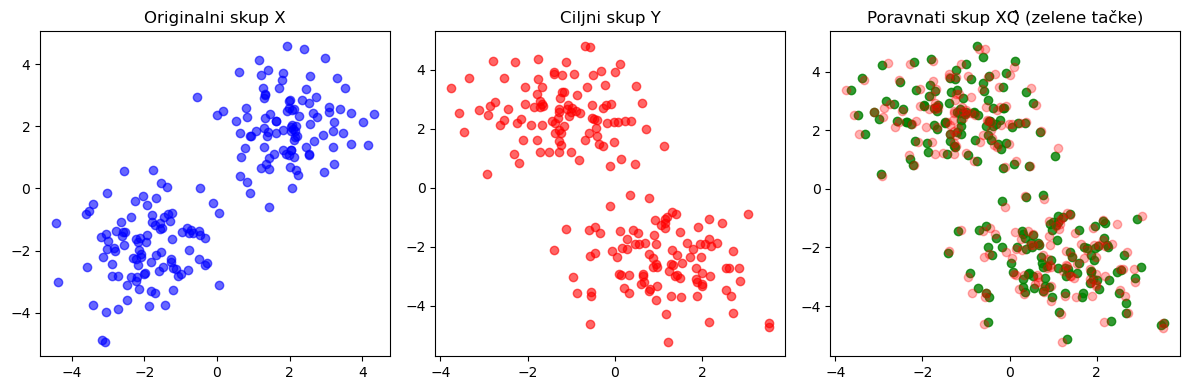

In [11]:
#np.random.seed(42)

# 1.
X = np.vstack([
    np.random.randn(100,2) + np.array([2,2]),
    np.random.randn(100,2) + np.array([-2,-2])
])

# 2.
theta = np.random.rand() * 2*np.pi
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])

sigma = 0.1
E = np.random.normal(0, sigma, X.shape)

Y = X @ R + E

# 3.
M = X.T @ Y
U, _, Vt = np.linalg.svd(M)
Q_hat = U @ Vt
X_aligned = X @ Q_hat

# 4.
total_error = np.linalg.norm(Y - X_aligned, 'fro')
noise_error = np.linalg.norm(E, 'fro')
rotation_error = np.linalg.norm(X@R - X_aligned, 'fro')

print("Ukupna greška:", total_error)
print("Deo od šuma:", noise_error)
print("Deo od rotacije:", rotation_error)

# vizualizacija
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.scatter(X[:,0], X[:,1], c='blue', alpha=0.6)
plt.title("Originalni skup X")

plt.subplot(1,3,2)
plt.scatter(Y[:,0], Y[:,1], c='red', alpha=0.6)
plt.title("Ciljni skup Y")

plt.subplot(1,3,3)
plt.scatter(X_aligned[:,0], X_aligned[:,1], c='green', alpha=0.8)
plt.scatter(Y[:,0], Y[:,1], c='red', alpha=0.3, label='Y')
plt.title("Poravnati skup XQ̂ (zelene tačke)")

plt.tight_layout()
plt.show()

**б) Прокруст vs. Линеарна регресија (Критичка анализа):**
1. Решити исти проблем поравнања користећи обичну линеарну регресију (без ограничења на ортогоналност матрице трансформације): $XW = Y \Longrightarrow W = (X^TX)^{-1}X^TY$.
2. Упоредити грешке поравнања $\|X\hat{Q} - Y\|_F$ и $\|XW - Y\|_F$. Који метод даје мању грешку на тренинг подацима?
3. Дискутовати геометријске последице: Шта трансформација $W$ ради подацима што Прокрустова трансформација $Q$ не сме (нпр. скалирање, смицање)? Зашто је у AI задацима поравнања простора значења (нпр. *cross-lingual mapping*) често пожељније користити ортогонално поравнање упркос нешто већој грешци? 

(10 поена)

In [12]:
# 1.
W = np.linalg.inv(X.T @ X) @ X.T @ Y
X_reg = X @ W

# 2.
error_procrustes = np.linalg.norm(X_aligned - Y, 'fro')
error_regression = np.linalg.norm(X_reg - Y, 'fro')

print("Greška Prokrust:", error_procrustes)
print("Greška Linearna regresija:", error_regression)

Greška Prokrust: 1.9625129201025515
Greška Linearna regresija: 1.9393778427827175


Na treniranim podacima, linearna regresija uvek daje manju ili jednaku grešku jer nema ograničenje ortogonalnosti, tj. može da koristi i skaliranje i smicanje da minimizuje razliku.

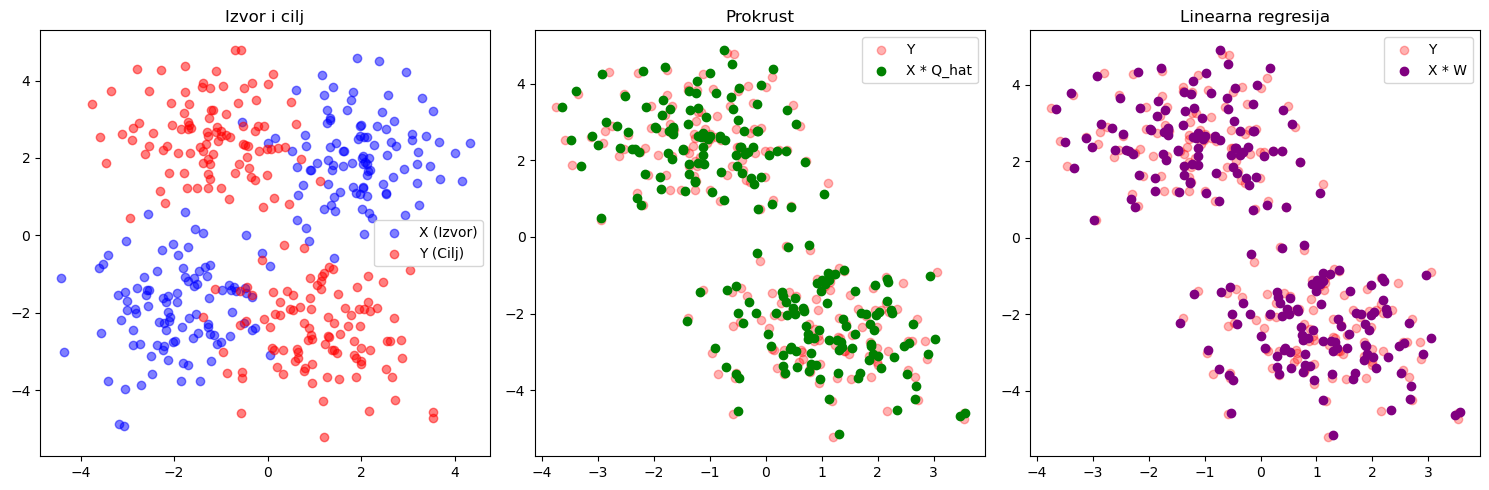

In [13]:
plt.figure(figsize=(15, 5))

# originalni i ciljni
plt.subplot(1, 3, 1)
plt.scatter(X[:, 0], X[:, 1], c='blue', alpha=0.5, label='X (Izvor)')
plt.scatter(Y[:, 0], Y[:, 1], c='red', alpha=0.5, label='Y (Cilj)')
plt.title("Izvor i cilj")
plt.legend()

# Prokrustovo poravnanje
plt.subplot(1, 3, 2)
plt.scatter(Y[:, 0], Y[:, 1], c='red', alpha=0.3, label='Y')
plt.scatter((X @ Q_hat)[:, 0], (X @ Q_hat)[:, 1], c='green', label='X * Q_hat')
plt.title("Prokrust")
plt.legend()

# poravnanje linearnom regresijom
plt.subplot(1, 3, 3)
plt.scatter(Y[:, 0], Y[:, 1], c='red', alpha=0.3, label='Y')
plt.scatter((X @ W)[:, 0], (X @ W)[:, 1], c='purple', label='X * W')
plt.title("Linearna regresija")
plt.legend()

plt.tight_layout()
plt.show()

Pored rotacije i refleksije, matrica linearne regresije $W$ vrši još i skaliranje i smicanje. 

U zadacima poput *cross-lingual mapping* ili *domain adaptation*, cilj je da se očuva semantička struktura prostora (relativne udaljenosti i uglovi između vektora). Ako dozvolimo skaliranje i smicanje, semantička geometrija se narušava i odnosi između pojmova postaju neupotrebljivi. Zato se koristi ortogonalno poravnanje (iako može imati nešto veću grešku na trening podacima) jer garantuje da će se semantička struktura očuvati. Samim tim, ortogonalno poravnanje generalizuje dosta bolje na neviđenim podacima (nema *overfitting*-a), iako daje naizgled "lošiji" rezultat na samom trening setu.

**в) Растезање израза и уочавање проблема (Аналитички део):**
1. Развити израз $\|QXU - Y\|_F^2$ користећи особине трага. Доказати да је минимизација овог израза еквивалентна максимизацији функције $f(Q, U) = {\rm tr}(Q X U Y^T)$.
2. Објаснити зашто решење из материјала ($Q = V W^T$ за $X^TY = V\Sigma W^T$) овде не може директно да се примени. У чему се огледа „спрегнутост” (coupling) матрица $Q$ и $U$ у овом изразу? 

(5 поена)

**1.**

Koristimo osnovnu vezu između Frobenijusove norme i traga matrice: $\|A\|_F^2 = {\rm tr}(A^T A)$, kao i linearnost traga i njegovu cikličnu osobinu ${\rm tr}(AB) = {\rm tr}(BA)$.
Potrebno je razviti izraz:
$$\|QXU - Y\|_F^2 = {\rm tr}\left( (QXU - Y)^T (QXU - Y) \right)$$

Primenjujemo transponovanje na prvu zagradu (pravilo $(ABC)^T = C^T B^T A^T$):
$$= {\rm tr}\left( (U^T X^T Q^T - Y^T)(QXU - Y) \right)$$

Sada množimo "svaki sa svakim" unutar traga:
$$= {\rm tr}\left( U^T X^T Q^T Q X U - U^T X^T Q^T Y - Y^T Q X U + Y^T Y \right)$$

Zbog linearnosti traga, ovo možemo razdvojiti na četiri posebna traga. Zatim, koristimo činjenicu da su $Q$ i $U$ ortogonalne matrice, što znači da važi $Q^T Q = I$ i $U U^T = I$.

Prvi član: ${\rm tr}(U^T X^T Q^T Q X U) = {\rm tr}(U^T X^T I X U) = {\rm tr}(U^T X^T X U)$. Primenom cikličnog svojstva traga prebacujemo $U^T$ na kraj: ${\rm tr}(X^T X U U^T) = {\rm tr}(X^T X I) = {\rm tr}(X^T X) = \|X\|_F^2$.

Četvrti član: ${\rm tr}(Y^T Y) = \|Y\|_F^2$.

Srednji članovi: Član ${\rm tr}(U^T X^T Q^T Y)$ je zapravo transponovana verzija člana ${\rm tr}(Y^T Q X U)$. 

Pošto je trag matrice jednak tragu njene transponovane matrice, ova dva člana su jednaka. Takođe, primenom ciklične osobine na ${\rm tr}(Y^T Q X U)$ prebacujemo $Y^T$ na kraj: ${\rm tr}(Q X U Y^T)$.

Zamenom svega ovoga nazad u jednačinu, dobijamo uprošćen izraz:
$$\|QXU - Y\|_F^2 = \|X\|_F^2 + \|Y\|_F^2 - 2 {\rm tr}(Q X U Y^T)$$

Dakle, pošto su $\|X\|_F^2$ i $\|Y\|_F^2$ konstante (zavise isključivo od fiksiranih ulaznih podataka, ortogonalne transformacije ne menjaju njihovu normu), minimizacija cele jednačine svodi se isključivo na maksimizaciju negativnog člana. Dakle, problem je matematički ekvivalentan maksimizaciji funkcije:
$$f(Q, U) = {\rm tr}(Q X U Y^T)$$

**2.**

U standardnom Prokrustovom problemu, gde tražimo samo jednu matricu $Q$ minimizujući $\|XQ - Y\|_F^2$, rešenje je direktno - izračunamo SVD dekompoziciju matrice $X^T Y = V \Sigma W^T$, i rešenje je $Q = V W^T$.

Međutim, ovde tražimo dve ortogonalne matrice ($Q$ i $U$) koje množe matricu $X$ sa obe strane. Maksimizujemo funkciju $f(Q, U) = {\rm tr}(Q X U Y^T)$. Spregnutost znači da optimalno rešenje za jednu matricu zavisi od trenutne vrednosti druge matrice - ako fiksiramo $U$ i posmatramo to kao konstantu, onda je optimalno $Q$ funkcija od $U$.
Ako fiksiramo $Q$ i posmatramo to kao konstantu, optimalno $U$ je funkcija od $Q$. 

Zbog ove međusobne zavisnosti, $Q$ i $U$ su "spregnute" i ne možemo ih razdvojiti da bismo dobili jedno konačno rešenje u jednom koraku koristeći samo SVD matrice $X^T Y$. Ovakvi problemi sa spregnutim promenljivama se u praksi rešavaju iterativnim optimizacionim algoritmima gde u jednoj iteraciji fiksiramo $U$ i optimizujemo $Q$, a u sledećoj fiksiramo $Q$ i optimizujemo $U$, sve dok proces ne konvergira.

**г) Пут ка решењу преко SVD декомпозиција (Истраживачки део):**
Уместо рачунања SVD-а производа, размотримо појединачне SVD декомпозиције:
$$X = U_X \Sigma_X V_X^T \quad \text{и} \quad Y = U_Y \Sigma_Y V_Y^T$$
1. Интуитивно објаснити: Ако желимо да матрица $X$ „личи” на $Y$, шта би оптималне трансформације $Q$ и $U$ требало да ураде са главним правцима (сингуларним векторима) матрице $X$ у односу на главне правце матрице $Y$?
2. Користећи ову интуицију, предложити форме за $Q$ и $U$ преко матрица сингуларних вектора $U_X, U_Y, V_X, V_Y$. 

(10 поена)

Pošto su $Q$ i $U$ ortogonalne matrice, one funkcionišu kao čiste rotacije (ili refleksije). One ne mogu da razvlače ili skupljaju prostor (tj. ne mogu da promene singularne vrednosti $\Sigma_X$ i $\Sigma_Y$). Njihov jedini zadatak je da rotiraju baze.

Dakle, ako želimo da matrica $X$ maksimalno "liči" na matricu $Y$, moramo da poravnamo koordinatne sisteme.

Matrica $Q$ (koja deluje sa leve strane) treba da rotira levi prostor glavnih pravaca matrice $X$ (bazu $U_X$) tako da se on savršeno poklopi sa levim prostorom matrice $Y$ (bazom $U_Y$).
Matrica $U$ (koja deluje sa desne strane) treba da rotira desni prostor glavnih pravaca matrice $X$ (bazu $V_X$) tako da se poklopi sa desnim prostorom matrice $Y$ (bazom $V_Y$).

Na osnovu ove intuicije, transformacija $Q X U$ treba da preuredi pravce matrice $X$ tako da njena SVD dekompozicija poprimi oblik što sličniji dekompoziciji matrice $Y$.

Ako zamenimo SVD dekompoziciju matrice $X$ u izraz:

$$Q X U = Q (U_X \Sigma_X V_X^T) U$$

i pošto matrice možemo da grupišemo, cilj nam je da postignemo sledeće poklapanje:

$$(Q U_X) \Sigma_X (V_X^T U) \approx U_Y \Sigma_Y V_Y^T$$

Da bismo poravnali leve i desne singularne vektore, postavljamo uslove:

Za levi prostor: $Q U_X = U_Y$

Za desni prostor: $V_X^T U = V_Y^T$

Pošto su $U_X$ i $V_X$ ortogonalne matrice (pa važi $U_X^{-1} = U_X^T$ i slično za $V_X$), iz ovih jednačina možemo direktno izraziti optimalne matrice $Q$ i $U$.

Za matricu $Q$ množimo prvu jednačinu sa $U_X^T$ sa desne strane i dobijamo:

$$Q = U_Y U_X^T$$

Za matricu $U$ množimo drugu jednačinu sa $V_X$ sa leve strane i dobijamo:

$$U = V_X V_Y^T$$

Kako bismo ovo proverili, možemo da zamenimo predložene izraze nazad u transformaciju čime dobijamo:

$$Q X U = (U_Y U_X^T) (U_X \Sigma_X V_X^T) (V_X V_Y^T)$$

$$= U_Y (U_X^T U_X) \Sigma_X (V_X^T V_X) V_Y^T$$

$$= U_Y \Sigma_X V_Y^T$$

Dobili smo matricu koja ima iste glavne pravce kao matrica $Y$ ($U_Y$ i $V_Y^T$), a jedina razlika koja je preostala potiče od singularnih vrednosti ($\Sigma_X$ naspram $\Sigma_Y$). 

S obzirom da ortogonalne transformacije po prirodi ne mogu da menjaju singularne vrednosti, ovo je matematički najbliže što $X$ može da priđe $Y$ u dvostranom Prokrustovom problemu bez upotrebe skaliranja.

**д) Нумеричка верификација и Клетва знака:**
1. Генерисати случајне матрице $X$ и $Y$ димензија $10 \times 10$. Израчунати оптималне $Q$ и $U$ преко предложене методе из тачке (б).
2. Израчунати вредност $\|QXU - Y\|_F$. 
3. **Изазов:** Код овог проблема постоји скривена замка — сингуларни вектори су дефинисани до на знак ($\pm u_i$). Како насумичан избор знака у SVD алгоритму може покварити поравнање? Предложити једноставну хеуристику како бисте осигурали да сингуларни вектори буду „кохерентно” оријентисани пре него што формирате $Q$ и $U$. 

(10 поена)

In [14]:
X = np.random.randn(10, 10)
Y = np.random.randn(10, 10)

Ux, Sx, Vxt = np.linalg.svd(X)
Uy, Sy, Vyt = np.linalg.svd(Y)

Vx = Vxt.T
Vy = Vyt.T

Q = Uy @ Ux.T
U = Vx @ Vy.T

X_aligned = Q @ X @ U

error = np.linalg.norm(X_aligned - Y, 'fro')
print("Greška: ", error)

Greška:  1.312235813360158


SVD dekompozicija $A = U \Sigma V^T$ nije jedinstvena u pogledu znaka. 
Važi sledeće pravilo:

$$( -u_i ) \sigma_i ( -v_i )^T = u_i \sigma_i v_i^T$$

Zbog ovoga, numerički algoritmi mogu nasumično obrnuti znakove određenih parova singularnih vektora. Kada formiramo transformacije $Q$ i $U$ tako što direktno množimo vektore iz SVD matrica $X$ i $Y$, ako je jedan vektor okrenut u suprotnom smeru, transformacija će umesto rotacije napraviti refleksiju (izvrtanje prostora), što dosta kvari poravnanje i povećava grešku.

Heuristika:

Da bismo osigurali da singularni vektori matrica $X$ i $Y$ budu usklađeni pre nego što formiramo $Q$ i $U$, možemo direktno uporediti njihove smerove.
Kao mera sličnosti smerova dva vektora može se iskoristiti njihov skalarni proizvod (koji je proporcionalan kosinusu ugla između njih). Za svaki par levih singularnih vektora računamo:
$$s_i = \langle u_i^X, u_i^Y \rangle$$

Ako je $s_i > 0$, vektori su orijentisani u "istom" smeru (ugao je manji od $90^\circ$).
Ako je $s_i < 0$, vektori su orijentisani na suprotne strane.
Kada detektujemo $s_i < 0$, primenjujemo jednostavnu korekciju: menjamo znak vektoru $u_i^Y$ i takođe menjamo znak vektoru $v_i^Y$ (odnosno $i$-tom redu matrice $V_Y^T$). Na ovaj način SVD dekompozicija matrice $Y$ ostaje matematički nepromenjena, ali su joj glavne ose sada usklađene sa osama matrice $X$.

***

**Задатак 4.**  Како победити „Клетву димензионалности”: Nyström апроксимација

У многим алгоритмима машинског учења (као што су SVM или Kernel PCA), уместо са оригиналним подацима $x \in \mathbb{R}^d$, радимо са њиховим нелинеарним пресликавањима у простор веће димензије $\phi(x)$. Главна предност овог приступа је **Кернел трик**: уместо експлицитног рачунања $\phi(x)$, израчунавамо само скаларни производ у том простору преко кернел функције: $\kappa(x_i, x_j) = \langle \phi(x_i), \phi(x_j) \rangle$.

За скуп од $N$ података формирамо Кернел матрицу (Грамову матрицу) $K \in \mathcal{M}_{N \times N}$, где је сваки елемент $K_{ij}$ мера сличности између тачака $i$ и $j$. Најчешће коришћени је **RBF кернел**:
$$K_{ij} = \exp\!\left(-\gamma \,\lVert x_i - x_j \rVert^{2}\right)$$

У раду са великим подацима ($N > 10^5$), израчунавање пуне кернел матрице $K \in \mathcal{M}_{N \times N}$ и њене спектралне декомпозиције (за Kernel PCA) је рачунски немогуће због сложености $O(N^3)$. Решење је апроксимација малог ранга заснована на подскупу података.

**Контекст:** Поделимо податке на скуп „оријентира” (landmarks, $m$ тачака) и остатак ($n-m$ тачака), где је $m \ll n$. Матрицу $K$ записујемо у блок форми:
$$K = \begin{bmatrix} 
W & B \\ 
B^T & C 
\end{bmatrix}$$
где је $W \in \mathcal{M}_{m \times m}$ сличност међу оријентирима, а $B \in \mathcal{M}_{m \times (n-m)}$ сличност између оријентира и осталих тачака.

**а) Конструкција „уског грла” (Bottleneck):** 
Nyström апроксимација претпоставља да се блок $C$ може апроксимирати користећи само информације из блокова $W$ и $B$ као $\tilde{C} = B^T W^{-1} B$. 
1. Доказати да се тада цела апроксимирана матрица $\tilde{K}$ може записати у факторисаном облику:
$$\tilde{K} = \begin{bmatrix} W \\ B^T \end{bmatrix} W^{-1} \begin{bmatrix} W & B \end{bmatrix}$$
2. Који је максимални могући ранг матрице $\tilde{K}$? Повежите ово са идејом компресије података. 

(5 поена)

Aproksimirana matrica je:

$$
\tilde{K} =
\begin{bmatrix}
W & B \\
B^T & B^T W^{-1} B
\end{bmatrix}
$$

Sada računamo proizvod:

$$
\begin{bmatrix}
W \\
B^T
\end{bmatrix}
W^{-1}
\begin{bmatrix}
W & B
\end{bmatrix}
$$

Sprovodimo množenje:

$$
W^{-1}
\begin{bmatrix}
W & B
\end{bmatrix}
=
\begin{bmatrix}
I & W^{-1} B
\end{bmatrix}
$$


$$
\begin{bmatrix}
W \\
B^T
\end{bmatrix}
\begin{bmatrix}
I & W^{-1} B
\end{bmatrix}
=
\begin{bmatrix}
W & B \\
B^T & B^T W^{-1} B
\end{bmatrix}
$$

Dakle važi faktorizacija:

$$
\tilde{K}
=
\begin{bmatrix}
W \\
B^T
\end{bmatrix}
W^{-1}
\begin{bmatrix}
W & B
\end{bmatrix}
$$

Rang $\tilde {K}$ je ograničen rangom faktora $\left[ \begin{matrix}W\\ B^T\end{matrix}\right]$, koji ima najviše $m$ kolona. Dakle:
$$\mathrm{rank}(\tilde {K})\leq m$$

To znači da Nyström aproksimacija kompresuje originalnu kernel matricu dimenzije $n\times n$ na matricu maksimalnog ranga $m$.

To dalje znači da umesto da čuvamo i računamo punu kernel matricu $K$ koja zahteva $O(n^2)$ memorije (što za $10^5$ tačaka znači $10^{10}$ elemenata), mi je aproksimiramo. Potrebno je da u memoriji čuvamo samo matricu $W$ (dimenzija $m \times m$) i matricu $B$ (dimenzija $m \times (n-m)$). Memorijska složenost pada sa $O(n^2)$ na $O(nm)$. Ako je $m \ll n$, ušteda je ogromna.

**б) Нумеричка имплементација и ефикасност:**
Уместо инверза $W^{-1}$ (који може бити нестабилан), користимо Мур-Пенроуз псеудоинверз $W^+$.
1. Генерисати нелинеаран скуп података (нпр. концентрични кругови или „месеци” из `sklearn.datasets`) са $N=1000$ тачака.
2. Изабрати насумично $m=50$ тачака као оријентире.
3. Израчунати апроксимацију $\tilde{K} = K_{nm} W^+ K_{nm}^T$, где је $K_{nm} = \begin{bmatrix} W \\ B^T \end{bmatrix}$.
4. Измерити време потребно за рачунање SVD декомпозиције пуне матрице $K$ у односу на апроксимацију $\tilde{K}$ (дискутовати зашто је за велике $N$ разлика огромна).

(10 поена)

In [15]:
# 1.
np.random.seed(42)
N = 1000
X, y = make_circles(n_samples=N, noise=0.05, factor=0.5)

# 2.
m = 50
indices = np.random.choice(N, m, replace=False)
X_landmarks = X[indices]

# 3. i 4.
gamma = 5.0
start_full = time.time()
K = rbf_kernel(X, X, gamma=gamma)
U_full, S_full, Vt_full = np.linalg.svd(K, full_matrices=False)
time_full = time.time() - start_full

# računamo i vreme potrebno za formiranje matrica W i K_nm kako bi poređenje bilo pravednije
start_time_nystrom = time.time()
W = rbf_kernel(X_landmarks, X_landmarks, gamma=gamma)
K_nm = rbf_kernel(X, X_landmarks, gamma=gamma)
W_pinv = np.linalg.pinv(W)

# SVD Nystrom aproksimacije se računa efikasnije na osnovu https://www.jmlr.org/papers/volume6/drineas05a/drineas05a.pdf
# pošto je W_pinv pozitivno semidefinitna, možemo je razložiti na L*L^T
# zatim radimo SVD na mnogo manjoj matrici M = K_nm * L (dimenzija N x m)
U_w, S_w, Vt_w = np.linalg.svd(W_pinv)
L = U_w @ np.diag(np.sqrt(np.abs(S_w))) @ Vt_w
M = K_nm @ L

# SVD na M (mnogo brže jer je M uska matrica N x m)
U_approx, S_M, Vt_approx = np.linalg.svd(M, full_matrices=False)
S_approx = S_M**2 

end_time_nystrom = time.time()
time_nystrom = end_time_nystrom - start_time_nystrom

print("Vreme SVD pune matrice:", time_full, "sekundi")
print("Vreme SVD Nystrom aproksimacije:", time_nystrom, "sekundi")

# eksplicitno računanje aproksimacije (samo zbog merenja greške)
K_tilde_explicit = K_nm @ W_pinv @ K_nm.T
approximation_error = np.linalg.norm(K - K_tilde_explicit, 'fro') / np.linalg.norm(K, 'fro')
print(f"Relativna greška aproksimacije:   {approximation_error:.4f}")

Vreme SVD pune matrice: 0.2642855644226074 sekundi
Vreme SVD Nystrom aproksimacije: 0.007601022720336914 sekundi
Relativna greška aproksimacije:   0.0272


Kada posmatramo vremensku složenost, algoritam za računanje SVD dekompozicije nad punom matricom $K$ ima vremensku složenost $\mathcal{O}(N^3)$.
S druge strane, implementacija Nystrom metode svodi problem na rad sa uskim matricama ($W$ dimenzija $m \times m$ i $M$ dimenzija $N \times m$). Složenost tog pristupa je $\mathcal{O}(Nm^2 + m^3)$. Ako imamo mali skup kao u kodu iznad, onda ni računanje SVD nad celom matricom $K$ ne traje mnogo dugo (oko $0.6$ sekundi).
Međutim, ako radimo sa pravim velikim skupom (npr. gde je $N=10^5$ ili više), onda računanje čitave matrice $K$ i njene SVD dekompozicije bi praktično bilo nemoguće (predugo izvršavanje i velika količina memorije). Zbog toga Nystrom aproksimacija i optimizovano računanje SVD dekompozicije donose znatno ubrzanje (npr. za $N=100 000$ potrebno vreme je pola sekunde).

**в) Анализа квалитета (Frobenius vs Eckart-Young):**

1. Израчунати грешку апроксимације у Фробенијусовој норми: $E_{nys} = \|K - \tilde{K}\|_F$.
2. Користећи Eckart-Young-Mirsky теорему, израчунати теоријски минималну могућу грешку апроксимације ранга $m$ за матрицу $K$: $E_{min} = \|K - K_m\|_F$.
3. Упоредити $E_{nys}$ и $E_{min}$. Дискутовати: зашто у пракси прихватамо нешто већу грешку Nyström методе? Како избор „оријентира” (насумично vs. $k$-means центроиди) може утицати на то да се $E_{nys}$ приближи вредности $E_{min}$? 

(10 поена)

In [16]:
E_nys = np.linalg.norm(K - K_tilde_explicit, 'fro')

# prema teoremi, greška optimalne aproksimacije ranga m jednaka je
# kvadratnom korenu sume kvadrata svih preostalih singularnih vrednosti
E_min = np.sqrt(np.sum(S_full[m:]**2))

print(f"E_nys: {E_nys:.4f}")
print(f"E_min: {E_min:.4f}")

E_nys: 7.3115
E_min: 0.3213


Prema Eckart-Young-Mirsky teoremi, najmanja moguća greška aproksimacije matrice $K$ matricom ranga $m$ iznosi:

$$E_{min} = \sqrt{\sum_{i=m+1}^N \sigma_i^2}$$

S obzirom na to da Nyström metoda takođe generiše aproksimaciju $\tilde{K}$ čiji je rang najviše $m$, njena greška $E_{nys} = \|K - \tilde{K}\|_F$ matematički nikada ne može biti manja od ovog teorijskog optimuma. Dakle, uvek važi:

$$E_{nys} \ge E_{min}$$

što je i potvrđeno gornjim kodom.

U praksi prihvatamo nešto veću grešku kod Nyström metode jer da bismo dostigli optimalnu grešku $E_{min}$, morali bismo da izračunamo punu SVD dekompoziciju matrice $K$, što zahteva složenost $\mathcal{O}(N^3)$. Za velike skupove podataka, ovo je hardverski nemoguće izvesti. Dakle, svesno žrtvujemo malo preciznosti (što rezultira nešto većom greškom) zarad ogromne uštede u vremenu i memoriji.

Kvalitet aproksimacije direktno zavisi od toga koliko dobro $m$ izabranih orijentira reprezentuje celokupan prostor podataka. Nasumičan izbor je veoma brz i računski jeftin, ali može slučajno propustiti cele klastere podataka ili loše pokriti prostor. Zbog toga potprostor koji orijentiri formiraju može biti neoptimalan, što rezultira većim odstupanjem $E_{nys}$ od $E_{min}$.
Ako prvo iskoristimo *K-means* algoritam da pronađemo $m$ centara, oni će ravnomerno pokriti celokupnu distribuciju podataka. Zahvaljujući tome, aproksimacija postaje znatno preciznija, a $E_{nys}$ se značajno približava teorijskom minimumu $E_{min}$.

***

**Задатак 5.** Класификација цифара методом потпростора (MNIST)

У овом задатку истражујемо моћ моделовања класа као потпростора ниске димензије. Циљ је да се превазиђе обичан PCA приступ увођењем трансформације која мапира потпросторе тако да они постану „што више ортогонални” једни на друге.

**а)** 
1. Из MNIST базе издвојити податке за цифре {0, 1, 4, 8, 9}. Поделити податке на тренинг и тест скуп (нпр. 80/20%).
2. За сваку класу израчунати средњи вектор $\mu_i$ и матрицу ортонормиране базе $U_i \in \mathcal{M}_{784 \times k}$ користећи првих $k=20$ главних компоненти центрираних података те класе. 
3. Визуелизовати првих 5 главних компоненти за цифре 4 и 9. Прокоментарисати сличности у њиховим спектралним структурама.

(5 поена)

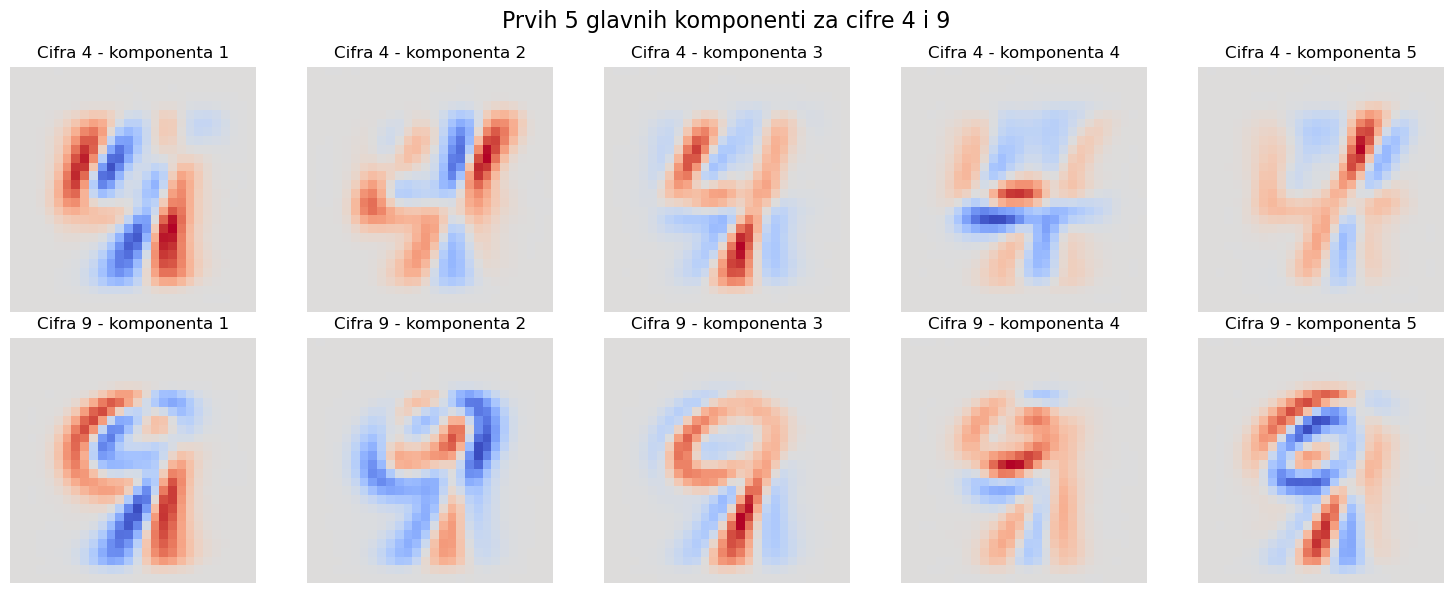

In [17]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')
X, y = mnist.data, mnist.target.astype(int)

valid_classes = [0, 1, 4, 8, 9]
mask = np.isin(y, valid_classes)
X_filtered = X[mask]
y_filtered = y[mask]

X_train, X_test, y_train, y_test = train_test_split(
    X_filtered, y_filtered, test_size=0.2, random_state=42, stratify=y_filtered
)

k = 20
subspaces = {}

for cls in valid_classes:
    X_cls = X_train[y_train == cls]
    mi = np.mean(X_cls, axis=0)
    X_centered = X_cls - mi
    
    # V^T sadrži glavne pravce (komponente) u redovima
    _, _, Vt = np.linalg.svd(X_centered, full_matrices=False)
    
    # izdvajamo prvih k pravaca (redova iz Vt) i transponujemo da dobijemo Ui (784 x k)
    U_i = Vt[:k, :].T
    subspaces[cls] = {'mu': mi, 'U': U_i}

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Prvih 5 glavnih komponenti za cifre 4 i 9", fontsize=16)

for idx, cls in enumerate([4, 9]):
    U_cls = subspaces[cls]['U']
    for i in range(5):
        pc_image = U_cls[:, i].reshape(28, 28)
        
        ax = axes[idx, i]
        im = ax.imshow(pc_image, cmap='coolwarm', vmin=-np.max(np.abs(pc_image)), vmax=np.max(np.abs(pc_image)))
        ax.set_title(f"Cifra {cls} - komponenta {i+1}")
        ax.axis('off')

plt.tight_layout()
plt.show()

Prvih nekoliko glavnih komponenti cifara 4 i 9 pokazuju slične spektralne strukture (pogotovo prva komponenta), jer dominantne linije, konture i oblasti visokog kontrasta hvataju osnovne oblike cifara. Ove sličnosti objašnjavaju zašto nekim klasifikatorima razdvajanje cifara 4 i 9 može biti izazovno i ukazuju na potrebu za dodatnim tehnikama radi bolje diskriminacije klasa.

**б)** 
1. За сваку слику $v$ из тест скупа, израчунати пројекције на сваки од 5 потпростора: $v_{proj, i} = U_i U_i^T (v - \mu_i)$.
2. Израчунати Еуклидско растојање (резидуал) до сваког потпростора: $d_i(v) = \|(v - \mu_i) - v_{proj, i}\|_2$.
3. Класификовати тест слике на основу минималног растојања и приказати матрицу конфузије.

(5 поена)

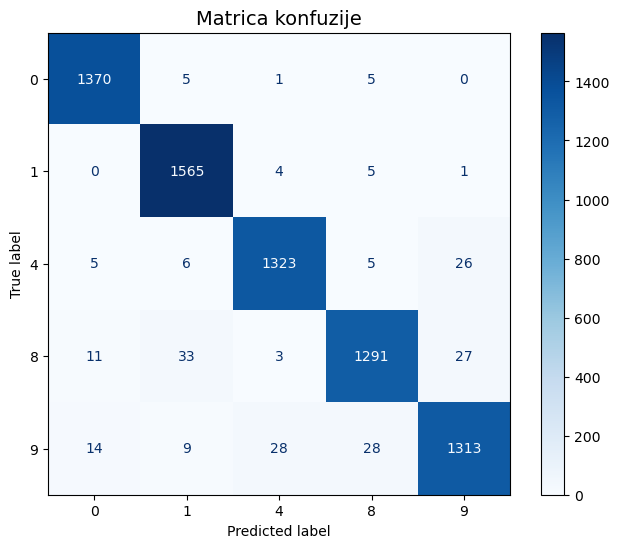

In [18]:
# matrica u kojoj ćemo čuvati rastojanja za svaku klasu (broj_test_slika x broj_klasa)
num_classes = len(valid_classes)
distances = np.zeros((X_test.shape[0], num_classes))

for idx, cls in enumerate(valid_classes):
    mu_i = subspaces[cls]['mu']
    U_i = subspaces[cls]['U']
    
    V_centered = X_test - mu_i
    
    V_proj = U_i @ U_i.T @ V_centered.T
    
    V_residual = V_centered - V_proj.T
    
    d_i = np.linalg.norm(V_residual, axis=1)
    
    distances[:, idx] = d_i

# indeksi najmanjih rastojanja
min_distance_indices = np.argmin(distances, axis=1)

# mapiramo indekse nazad u stvarne klase
y_pred = np.array([valid_classes[i] for i in min_distance_indices])

cm = confusion_matrix(y_test, y_pred, labels=valid_classes)

plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=valid_classes)
disp.plot(cmap='Blues', values_format='d', ax=plt.gca())
plt.title('Matrica konfuzije', fontsize=14)
plt.show()

**в)** 
1. Идентификовати две цифре које се најчешће мешају (нпр. 4 и 9).
2. Израчунати каноничке углове између њихових потпростора $U_4$ и $U_9$ (сингуларне вредности матрице $U_4^T U_9$). 
3. Колико каноничких углова је близу нуле (тј. $\cos \theta \approx 1$)? Објаснити везу између ових углова и грешака у матрици конфузије.

(5 поена)

Najčešće se mešaju $4$ i $9$, i $8$ i $9$. Za ovaj deo odabraćemo $4$ i $9$.

In [19]:
U4 = subspaces[4]['U']
U9 = subspaces[9]['U']

M = U4.T @ U9
_, S, _ = np.linalg.svd(M)

print(S)

close_to_zero_angles = np.sum(S > 0.95)
print("Broj kanoničkih uglova bliskih nuli:", close_to_zero_angles)

[0.98859159 0.98584579 0.96781911 0.96502812 0.95908316 0.93753211
 0.93417504 0.90696487 0.88379048 0.87710085 0.85494271 0.78895966
 0.75581267 0.70005677 0.60021778 0.48038169 0.40182999 0.3030111
 0.2289286  0.10816388]
Broj kanoničkih uglova bliskih nuli: 5


Kanonički uglovi između potprostora dve klase mere koliko su njihovi dominantni pravci međusobno slični. Ako je $\cos \theta_i \approx 1$, odgovarajući kanonički ugao $\theta_i$ je blizu nule, što znači da postoje pravci iz ta dva potprostora koji su skoro paralelni.

U eksperimentu se vidi da su prve singularne vrednosti matrice $U_4^T U_9$ veoma blizu jedinici, što znači da su prvi kanonički uglovi relativno mali (npr. $0-20$ stepeni). To pokazuje da se potprostori cifara $4$ i $9$ značajno preklapaju duž nekoliko dominantnih pravaca, odnosno da imaju zajednički "deo" koji opisuje slične strukturne karakteristike slika.

Problem sa klasifikatorom zasnovanog na potprostorima je taj što dodeljuje sliku onoj klasi za koju je rezidual projekcije najmanji. Ako uzmemo sliku cifre $9$ i projektujemo je na potprostor cifre $4$, veliki deo te slike biće rekonstruisan pomoću pravaca koji su zajednički za oba potprostora. Zbog toga projekcija može biti veoma dobra, a rezidual postaje mali.

U slučajevima kada je cifra $9$ napisana na način koji liči na $4$ (npr. kada gornji krug nije potpuno zatvoren), potprostor cifre $4$ može čak bolje rekonstruisati takvu sliku nego potprostor cifre $9$, pa se može desiti da važi $d_4(v) < d_9(v)$. Tada klasifikator donosi pogrešnu odluku, što se manifestuje elementima van glavne dijagonale u matrici konfuzije.

**г)** SDA трансформација и побољшање сепарабилности:
1. Формирати матрице расипања $S_b$ и $S_w$.
2. Решити уопштени сопствени проблем $S_b w = \lambda S_w w$ (користећи „избељивање” простора или регуларизацију $S_w + \epsilon I$ како би инверзија била стабилна).
3. Одабрати матрицу трансформације $W$ састављену од првих $d=50$ уопштених сопствених вектора.
4. Трансформисати базе потпростора: $\tilde{U}_i = {\rm orth}(W^T U_i)$.
5. Поново израчунати каноничке углове између трансформисаних потпростора за цифре 4 и 9. Доказати нумерички да су углови сада већи (косинуси мањи) и дискутовати како ово директно помаже класификацији.

(10 поена)

In [44]:
d = X_train.shape[1]

mu_global = np.mean(X_train, axis=0)

# 1.
S_w = np.zeros((d, d))
S_b = np.zeros((d, d))

for cls in valid_classes:
    X_cls = X_train[y_train == cls]
    mu_i = np.mean(X_cls, axis=0)
    
    X_centered = X_cls - mu_i

    # https://www.geeksforgeeks.org/engineering-mathematics/problem-solving-on-scatter-matrix/
    # within the class scatter matrix
    S_w += X_centered.T @ X_centered
    
    # between the class scatter matrix
    n_i = X_cls.shape[0]
    diff = (mu_i - mu_global).reshape(-1,1)
    S_b += n_i * (diff @ diff.T)

# 2. 
epsilon = 1000
S_w_reg = S_w + epsilon * np.eye(d)
eigvals, eigvecs = np.linalg.eig(np.linalg.inv(S_w_reg) @ S_b)
idx = np.argsort(eigvals)[::-1]
eigvecs = eigvecs[:, idx]

# 3.
d_new = 50
W = eigvecs[:, :d_new]

# 4.
transformed_subspaces = {}
for cls in valid_classes:
    U_i = subspaces[cls]['U']
    U_tilde = orth(W.T @ U_i)
    transformed_subspaces[cls] = U_tilde

# 5.
U4 = subspaces[4]['U']
U9 = subspaces[9]['U']

U4_t = transformed_subspaces[4]
U9_t = transformed_subspaces[9]

_, S_before, _ = np.linalg.svd(U4.T @ U9)
_, S_after, _ = np.linalg.svd(U4_t.T @ U9_t)

print("Kosinus kanoničkih uglova pre transformacije:")
print(S_before)

print("\nKosinus kanoničkih uglova posle transformacije:")
print(S_after)

Kosinus kanoničkih uglova pre transformacije:
[0.98859159 0.98584579 0.96781911 0.96502812 0.95908316 0.93753211
 0.93417504 0.90696487 0.88379048 0.87710085 0.85494271 0.78895966
 0.75581267 0.70005677 0.60021778 0.48038169 0.40182999 0.3030111
 0.2289286  0.10816388]

Kosinus kanoničkih uglova posle transformacije:
[0.98543624 0.97839042 0.94238644 0.90050751 0.88273896 0.86094291
 0.83748297 0.81189068 0.77901893 0.70170474 0.67818192 0.55996286
 0.5023904  0.45865743 0.36367849 0.25530191 0.22806337 0.15513102
 0.11580746 0.03253277]


Rezultati pokazuju da se kosinusi kanoničkih uglova između potprostora cifara $4$ i $9$ smanjuju nakon transformacije, odnosno da se sami uglovi povećavaju (ali tek nakon što je $\epsilon$ stavljeno na $1000$, inače za manje vrednosti $\epsilon$ sprovedeni postupak ne povećava kanoničke uglove). To znači da su potprostori postali više ortogonalni.

SDA transformacija direktno poboljšava klasifikaciju jer menja reprezentaciju podataka tako da potprostori različitih klasa postanu međusobno razdvojeniji. U tom slučaju projekcija slike na pogrešan potprostor rekonstruiše znatno manji deo informacije slike, pa rezidual postaje veći za pogrešne klase. Zbog toga klasifikator koji bira klasu sa najmanjim rezidualom dobija jasniju razliku između tačnog i netačnog potprostora.

***